# TiRex: Zero-Shot Forecasting with an xLSTM Foundation Model

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/manmeet3591/time_series/blob/main/tirex_zero_shot.ipynb)

**Paper**: *TiRex: Zero-Shot Forecasting Across Long and Short Horizons with Enhanced In-Context Learning*. Auer, Podest, Klotz, Böck, Klambauer, Hochreiter. **NeurIPS 2025**. [arXiv:2505.23719](https://arxiv.org/abs/2505.23719)

**Official code**: [github.com/NX-AI/tirex](https://github.com/NX-AI/tirex) · **Weights**: [huggingface.co/NX-AI/TiRex](https://huggingface.co/NX-AI/TiRex) · **Package**: `tirex-ts` (pinned to 1.4.2 here)

**Key ideas**:
- **Recurrent backbone instead of a Transformer**: TiRex (35M parameters) stacks 12 **sLSTM** blocks from the xLSTM family. Its recurrent hidden state can do *state tracking*, which the authors argue Transformers and linear-RNN/SSM models handle poorly, and which helps over long horizons.
- **Patched quantile forecasting**: the series is cut into patches of 32 steps. Each patch, together with a missing-value mask, is embedded and passed through the sLSTM stack, and every output token is decoded into **9 quantiles** (0.1, …, 0.9) of the next 32 steps.
- **Contiguous Patch Masking (CPM)**: during pre-training, runs of consecutive patches are masked out as "missing". When forecasting past one patch, TiRex therefore does not feed its own point forecasts back in. It feeds *masked* patches and lets the recurrent state carry the uncertainty forward, which keeps the quantiles coherent over long horizons.
- **Zero-shot**: no training on ETTh1. We download the pre-trained weights and forecast.

| Component | Setting |
|---|---|
| Backbone | 12 × sLSTM block (d = 512, 4 heads) + RMSNorm |
| Patch size (in / out) | 32 / 32 |
| Pre-training context | 2048 steps (shorter inputs are NaN-padded on the left and masked) |
| Output | 9 quantiles; we use the **median (q=0.5)** as the point forecast |

**What this notebook does**: zero-shot, **channel-independent** (each of the 7 ETTh1 variables is forecast as its own univariate series) forecasting on the shared ETTh1 benchmark, horizon H = 96, with lookbacks **L = 512** (main foundation-model setting) and **L = 96** (the supervised-baseline setting). We report MSE/MAE of the median forecast and plot the quantile band.

## 0. Install

Colab already provides torch, numpy, pandas, matplotlib and scikit-learn. We add only `tirex-ts` (it pulls in `huggingface-hub`).

**GPU / CUDA-kernel note** (from the TiRex README): TiRex can use custom CUDA kernels for the sLSTM cell (`pip install "tirex-ts[cuda]"`, which installs `xlstm` and compiles the kernels with `nvcc` on first load). Those kernels **require compute capability ≥ 8.0** (Ampere or newer). The **Colab T4 is compute capability 7.5**, so it cannot use them. In `tirex-ts` 1.4.2, `load_model(...)` defaults to `backend="torch"`, a pure-PyTorch sLSTM that runs on any GPU (T4, A100, Blackwell) and on CPU. We use that backend everywhere in this notebook.

In [1]:
%pip install -q "tirex-ts==1.4.2"

Note: you may need to restart the kernel to use updated packages.


## 1. Imports, seed, device

In [2]:
import os, json, time, random, warnings
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 2024
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda:0" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", device,
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

torch 2.12.1+cu130 | device: cuda:0 | NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition


## 2. Data: ETTh1 with the standard splits

This is the setup shared by every notebook in this repo: 7 channels (HUFL…OT), the Informer/Autoformer borders 12/4/4 months for train/val/test, a `StandardScaler` fitted on the **train rows only**, and metrics computed in the scaled space, which is what papers report. TiRex is zero-shot, so the train split is used only to fit the scaler. The test split starts `L` steps early so the first test window has a full lookback.

In [3]:
URL = "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv"

def load_etth1(lookback):
    df = pd.read_csv(URL)
    data = df.drop(columns=["date"]).values.astype(np.float32)
    n_tr, n_va, n_te = 12*30*24, 4*30*24, 4*30*24
    scaler = StandardScaler().fit(data[:n_tr])
    data = scaler.transform(data).astype(np.float32)
    train = data[:n_tr]
    val = data[n_tr - lookback: n_tr + n_va]
    test = data[n_tr + n_va - lookback: n_tr + n_va + n_te]
    return train, val, test, df.columns[1:].tolist()

class WindowDataset(torch.utils.data.Dataset):
    def __init__(self, arr, L, H, stride=1):
        self.arr, self.L, self.H = arr, L, H
        self.idx = np.arange(0, len(arr) - L - H + 1, stride)
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]
        return torch.from_numpy(self.arr[i:i+self.L]), torch.from_numpy(self.arr[i+self.L:i+self.L+self.H])

H = 96
train, val, test, cols = load_etth1(512)
print("channels:", cols)
print("train/val/test shapes (L=512):", train.shape, val.shape, test.shape)

channels: ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
train/val/test shapes (L=512): (8640, 7) (3392, 7) (3392, 7)


## 3. sLSTM / xLSTM in one cell

xLSTM (Beck et al., NeurIPS 2024) modernises the LSTM with **exponential gating** and a **normaliser state**. The **sLSTM** variant used by TiRex keeps a *scalar* memory per unit and a true **recurrent** connection: the gates depend on the previous hidden state $h_{t-1}$ through block-diagonal (per-head) recurrent matrices $R$:

$$
\begin{aligned}
\tilde z_t &= W_z x_t + R_z h_{t-1} + b_z, & z_t &= \tanh(\tilde z_t)\\
\tilde i_t &= W_i x_t + R_i h_{t-1} + b_i, & i_t &= \exp(\tilde i_t)\\
\tilde f_t &= W_f x_t + R_f h_{t-1} + b_f, & f_t &= \sigma(\tilde f_t)\ \ (\text{sigmoid in TiRex; xLSTM also allows}\ \exp)\\
c_t &= f_t\, c_{t-1} + i_t\, z_t, & n_t &= f_t\, n_{t-1} + i_t\\
h_t &= o_t \odot \frac{c_t}{n_t}, & o_t &= \sigma(W_o x_t + R_o h_{t-1} + b_o)
\end{aligned}
$$

The exponentials are stabilised in log-space with a running maximum $m_t = \max(\log f_t + m_{t-1}, \log i_t)$. Exponential input gates let the cell *overwrite* its memory sharply when new evidence arrives, and the normaliser $n_t$ keeps $h_t$ bounded. Because of the $R h_{t-1}$ term, sLSTM cannot be parallelised over time the way mLSTM, Mamba or attention can. That is the price of state tracking, and it is why TiRex inference loops over the patch tokens: 64 tokens for a 2048-step context. The custom CUDA kernels fuse this loop. The `torch` backend runs it as a Python loop of small matmuls.

In TiRex each block is `x + sLSTM(RMSNorm(x))` followed by `x + FFN(RMSNorm(x))`, where the FFN is gated (SiLU). A residual MLP embeds each `[patch values ‖ NaN-mask]` token, and another decodes the final hidden state into `9 × 32` quantile values.

## 4. Load the pre-trained model

`load_model` downloads `model.ckpt` from the Hugging Face Hub, about 140 MB. We choose `backend="torch"` explicitly, as explained in §0.

In [4]:
from tirex import load_model

t0 = time.time()
model = load_model("NX-AI/TiRex", device=device, backend="torch")
n_params = sum(p.numel() for p in model.parameters())
cfg = model.config
print(f"loaded in {time.time()-t0:.1f}s | params: {n_params/1e6:.1f}M")
print("patch size:", cfg.input_patch_size, "| train context:", cfg.train_ctx_len,
      "| quantiles:", cfg.quantiles)
print("blocks:", cfg.block_kwargs["num_blocks"], "| d_model:", cfg.block_kwargs["embedding_dim"],
      "| heads:", cfg.block_kwargs["num_heads"])

loaded in 0.7s | params: 35.3M
patch size: 32 | train context: 2048 | quantiles: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
blocks: 12 | d_model: 512 | heads: 4


## 5. Zero-shot evaluation, batched on the GPU

Each test window × channel is an independent univariate context of length `L`. That gives `n_windows × 7` series, which we pass to `model.forecast(...)` in GPU batches.

- `max_accelerated_rollout_steps=3`: H = 96 is exactly 3 output patches. Instead of three sequential forward passes, each appending one masked patch, TiRex appends the 2 future patches as masked (NaN) tokens and emits all 3 patches in **one** pass. This is the CPM-style multi-patch inference the model was pre-trained for, and it is about 3× faster. In our checks the change in MSE was negligible.
- Point forecast = **median** (q = 0.5), which TiRex also returns as its `mean` output. MSE/MAE are averaged over all windows, horizon steps and channels.
- **Stride**: the shared protocol uses stride 1, i.e. all 2785 windows. The pure-torch sLSTM loop is slow on older GPUs, so this notebook uses stride 1 on GPUs with compute capability ≥ 8.0 and falls back to **stride 4** on a T4 or CPU, keeping the run under about 10 minutes. The stride used is printed and saved in the results JSON. Set `STRIDE` by hand to override.

In [5]:
QUANTILES = np.array(cfg.quantiles)
BATCH = 1024 if torch.cuda.is_available() else 128
cc = torch.cuda.get_device_capability(0) if torch.cuda.is_available() else (0, 0)
STRIDE = 1 if cc[0] >= 8 else 4
print("compute capability:", cc, "-> STRIDE =", STRIDE, "| batch size =", BATCH)

def make_windows(test, L, H, stride):
    # (N, L+H, C) sliding windows over the test split
    from numpy.lib.stride_tricks import sliding_window_view
    w = sliding_window_view(test, L + H, axis=0)[::stride]  # (N, C, L+H)
    return np.ascontiguousarray(w.transpose(0, 2, 1))

def evaluate_tirex(L, stride=STRIDE):
    _, _, test, _ = load_etth1(L)
    win = make_windows(test, L, H, stride)               # (N, L+H, C)
    N, _, C = win.shape
    ctx = torch.from_numpy(win[:, :L, :].transpose(0, 2, 1).reshape(N * C, L))  # (N*C, L)
    y = win[:, L:, :]                                    # (N, H, C)
    if torch.cuda.is_available(): torch.cuda.synchronize()
    t0 = time.time()
    q, med = model.forecast(ctx, prediction_length=H, batch_size=BATCH,
                            output_type="numpy", max_accelerated_rollout_steps=3)
    if torch.cuda.is_available(): torch.cuda.synchronize()
    secs = time.time() - t0
    q = q.reshape(N, C, H, len(QUANTILES)).transpose(0, 2, 1, 3)   # (N, H, C, Q)
    med = med.reshape(N, C, H).transpose(0, 2, 1)                   # (N, H, C)
    err = med - y
    res = dict(L=L, stride=stride, n_windows=N, n_series=N * C, seconds=secs,
               mse=float((err ** 2).mean()), mae=float(np.abs(err).mean()),
               mse_per_channel=(err ** 2).mean(axis=(0, 1)), mse_per_step=(err ** 2).mean(axis=(0, 2)))
    # probabilistic diagnostics: 10-90% interval coverage and mean weighted quantile loss
    res["cov_10_90"] = float(((y >= q[..., 0]) & (y <= q[..., -1])).mean())
    diff = y[..., None] - q
    ql = np.maximum(QUANTILES * diff, (QUANTILES - 1) * diff).sum(axis=(0, 1, 2))
    res["wql"] = float((2 * ql / np.abs(y).sum()).mean())
    print(f"L={L:4d}: {N} windows x {C} ch = {N*C} series in {secs:.1f}s | "
          f"MSE {res['mse']:.4f}  MAE {res['mae']:.4f} | 10-90% cov {res['cov_10_90']:.3f} | WQL {res['wql']:.3f}")
    return res, win, q, med

results = {}
results[512], win512, q512, med512 = evaluate_tirex(512)

compute capability: (12, 0) -> STRIDE = 1 | batch size = 1024


L= 512: 2785 windows x 7 ch = 19495 series in 40.1s | MSE 0.3856  MAE 0.3792 | 10-90% cov 0.805 | WQL 0.370


In [6]:
results[96], win96, q96, med96 = evaluate_tirex(96)

L=  96: 2785 windows x 7 ch = 19495 series in 35.2s | MSE 0.4388  MAE 0.4011 | 10-90% cov 0.814 | WQL 0.405


## 6. Per-channel and per-step errors

TiRex sees each channel on its own, so the per-channel MSE shows which variables are hard to predict from their own history alone. The "useful load" channels HUFL/MUFL (and LUFL) dominate the error. Their scaled values swing sharply from day to day. The "useless load" channels and the oil temperature OT are much easier. The per-step curve shows how the error grows across the 96-hour horizon. A longer context helps most at long lead times.

      MSE L=512  MSE L=96
HUFL     0.8128    0.9252
HULL     0.2078    0.2283
MUFL     0.8471    0.9663
MULL     0.1688    0.1881
LUFL     0.4930    0.5739
LULL     0.1155    0.1306
OT       0.0543    0.0589


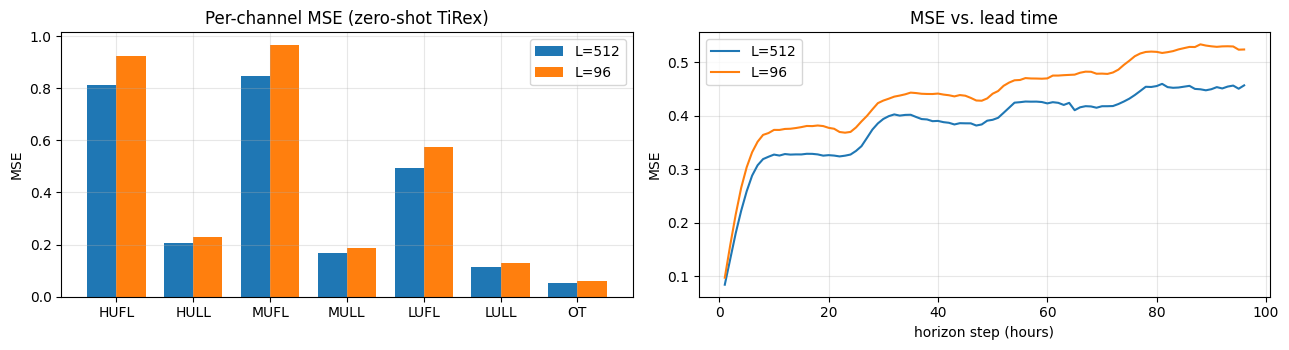

In [7]:
print(pd.DataFrame({f"MSE L={L}": results[L]["mse_per_channel"] for L in (512, 96)}, index=cols).round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
x = np.arange(len(cols)); w = 0.38
for k, L in enumerate((512, 96)):
    ax[0].bar(x + (k - 0.5) * w, results[L]["mse_per_channel"], w, label=f"L={L}")
    ax[1].plot(np.arange(1, H + 1), results[L]["mse_per_step"], label=f"L={L}")
ax[0].set_xticks(x); ax[0].set_xticklabels(cols); ax[0].set_ylabel("MSE"); ax[0].set_title("Per-channel MSE (zero-shot TiRex)")
ax[1].set_xlabel("horizon step (hours)"); ax[1].set_ylabel("MSE"); ax[1].set_title("MSE vs. lead time")
for a in ax: a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Forecast plot with the quantile band (OT channel)

History (last 192 of the 512 context steps), ground truth, TiRex median, and the 10–90% and 20–80% quantile bands, shown for a few test windows. All quantiles come from a single forward pass; there is no sampling.

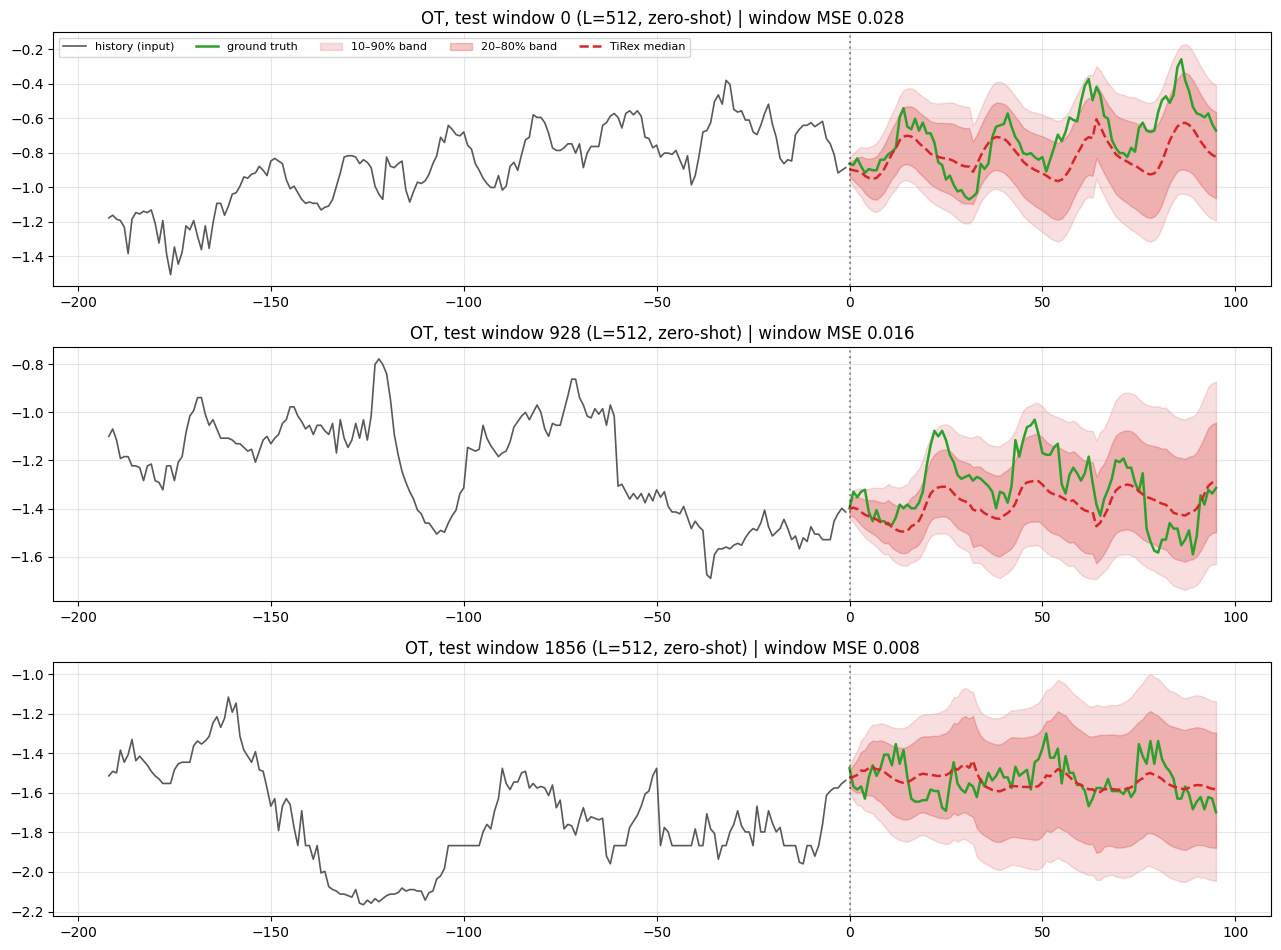

In [8]:
ot = cols.index("OT"); L = 512
show = [0, len(win512) // 3, 2 * len(win512) // 3]
fig, axes = plt.subplots(len(show), 1, figsize=(13, 3.2 * len(show)))
for ax, i in zip(axes, show):
    hist = win512[i, :L, ot][-192:]; truth = win512[i, L:, ot]
    th, tf = np.arange(-len(hist), 0), np.arange(0, H)
    ax.plot(th, hist, color="0.35", lw=1.2, label="history (input)")
    ax.plot(tf, truth, color="tab:green", lw=1.8, label="ground truth")
    ax.fill_between(tf, q512[i, :, ot, 0], q512[i, :, ot, -1], color="tab:red", alpha=0.15, label="10–90% band")
    ax.fill_between(tf, q512[i, :, ot, 1], q512[i, :, ot, -2], color="tab:red", alpha=0.25, label="20–80% band")
    ax.plot(tf, med512[i, :, ot], color="tab:red", lw=1.8, ls="--", label="TiRex median")
    ax.axvline(0, color="k", ls=":", alpha=0.4)
    mse_i = ((med512[i, :, ot] - truth) ** 2).mean()
    ax.set_title(f"OT, test window {i} (L=512, zero-shot) | window MSE {mse_i:.3f}")
    ax.grid(alpha=0.3)
axes[0].legend(loc="upper left", ncol=5, fontsize=8)
plt.tight_layout(); plt.show()

## 8. Results

All numbers are MSE/MAE on the standardized ETTh1 test split, horizon 96, averaged over windows, steps and all 7 channels.

**Published reference**: the TiRex paper evaluates on GIFT-Eval and Chronos-ZS using MASE/CRPS/WQL. It reports **no ETTh1 96→96 MSE/MAE** (ETT appears only inside GIFT-Eval), so `paper_mse/paper_mae` are `null`. For context we print the supervised TSLib references (L=96, trained on ETTh1).

In [9]:
REFS = {"DLinear": (0.386, 0.400), "PatchTST": (0.414, 0.419), "iTransformer": (0.386, 0.405), "TimesNet": (0.384, 0.402)}
print(f"{'Model':<34}{'L':>5}{'MSE':>9}{'MAE':>9}")
print("-" * 57)
for L in (512, 96):
    r = results[L]
    print(f"{'TiRex 35M (zero-shot, ours)':<34}{L:>5}{r['mse']:>9.4f}{r['mae']:>9.4f}")
print(f"{'TiRex paper (ETTh1 96→96)':<34}{'':>5}{'n/a':>9}{'n/a':>9}")
for k, (a, b) in REFS.items():
    print(f"{k + ' (supervised, TSLib)':<34}{96:>5}{a:>9.3f}{b:>9.3f}")
for L in (512, 96):
    r = results[L]
    print(f"\nL={L}: stride {r['stride']}, {r['n_series']} series, inference {r['seconds']:.1f}s, "
          f"10-90% coverage {r['cov_10_90']:.3f}, WQL {r['wql']:.3f}")

Model                                 L      MSE      MAE
---------------------------------------------------------
TiRex 35M (zero-shot, ours)         512   0.3856   0.3792
TiRex 35M (zero-shot, ours)          96   0.4388   0.4011
TiRex paper (ETTh1 96→96)                    n/a      n/a
DLinear (supervised, TSLib)          96    0.386    0.400
PatchTST (supervised, TSLib)         96    0.414    0.419
iTransformer (supervised, TSLib)     96    0.386    0.405
TimesNet (supervised, TSLib)         96    0.384    0.402

L=512: stride 1, 19495 series, inference 40.1s, 10-90% coverage 0.805, WQL 0.370

L=96: stride 1, 19495 series, inference 35.2s, 10-90% coverage 0.814, WQL 0.405


In [10]:
gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
for L, fname in ((512, "results_tirex_zero_shot.json"), (96, "results_tirex_zero_shot_L96.json")):
    try:
        r = results[L]
        out = {"model": "TiRex (35M, xLSTM/sLSTM, zero-shot)",
               "paper": "TiRex: Zero-Shot Forecasting Across Long and Short Horizons with Enhanced In-Context Learning (arXiv:2505.23719)",
               "venue": "NeurIPS 2025", "type": "zero-shot foundation",
               "lookback": L, "horizon": H, "mse": r["mse"], "mae": r["mae"],
               "paper_mse": None, "paper_mae": None, "params": int(n_params),
               "train_or_infer_seconds": round(r["seconds"], 2),
               "notes": (f"NX-AI/TiRex via tirex-ts 1.4.2, backend='torch' (pure-PyTorch sLSTM; custom CUDA kernels need "
                         f"compute capability >= 8.0, not available on T4); channel-independent univariate; median (q=0.5) "
                         f"forecast; max_accelerated_rollout_steps=3; stride {r['stride']} ({r['n_windows']} windows x 7 ch); "
                         f"10-90% coverage {r['cov_10_90']:.3f}; WQL {r['wql']:.3f}; GPU {gpu}. "
                         f"Paper reports only GIFT-Eval / Chronos-ZS (MASE/CRPS), no ETTh1 MSE.")}
        with open(fname, "w") as f: json.dump(out, f, indent=2)
        print("wrote", fname)
    except Exception as e:
        print("could not write results JSON:", e)

wrote results_tirex_zero_shot.json
wrote results_tirex_zero_shot_L96.json


## Using your own data

TiRex needs no training. Give it a 1D context (or a batch of contexts) and a horizon:

```python
import pandas as pd, torch
from tirex import load_model

model = load_model("NX-AI/TiRex", backend="torch")          # use backend="cuda" only on sm_80+ with `tirex-ts[cuda]`
df = pd.read_csv("my_series.csv", parse_dates=["timestamp"])
y = torch.tensor(df["value"].values, dtype=torch.float32)

quantiles, median = model.forecast(context=y[-2048:], prediction_length=168)   # (1, 168, 9), (1, 168)
# several series: pass a 2D tensor (n_series, length) or a list of 1D tensors of different lengths
```

Tips:
- **Context**: use up to 2048 points; longer inputs are truncated to the most recent 2048. Missing values may be `NaN`; TiRex masks them natively.
- **Scaling**: TiRex normalises each context internally, so raw units are fine. We standardise ETTh1 only so the metrics match the literature.
- **Multivariate data**: TiRex is univariate. Forecast each variable as its own series, as in this notebook. Batch them into one call.
- **Long horizons**: set `max_accelerated_rollout_steps=ceil(H/32)` to emit all output patches in one pass.